In [1]:
'''
see whether pca can help our light curves
'''

'\nsee whether pca can help our light curves\n'

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp
import corner


plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [4]:
#let's get a light curve to start out with

In [2]:
lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
lightcurve_path_filtered = '/lustre/lrspec/ZTF_data/lightcurves/1020_filtered/'
lc_filenames = np.load('/lustre/lrspec/ZTF_data/random_forest_training/lc_names_good.npy')
data = np.zeros((len(lc_filenames), len(lc)))
for i, filename in enumerate(lc_filenames):
    data[i] = np.array(pd.read_csv(lightcurve_path+filename)['flux_hap_'+str(2)])
# lcs = pd.read_csv(lightcurve_path+lc_filename)['flux_hap_'+str(2)]
# lc_filename_filtered = lc_filename[:-4]+"_filtered_hap2.csv"
# lc_filtered = pd.read_csv(lightcurve_path_filtered+lc_filename_filtered)['flux_hap_'+str(2)]


NameError: name 'lc' is not defined

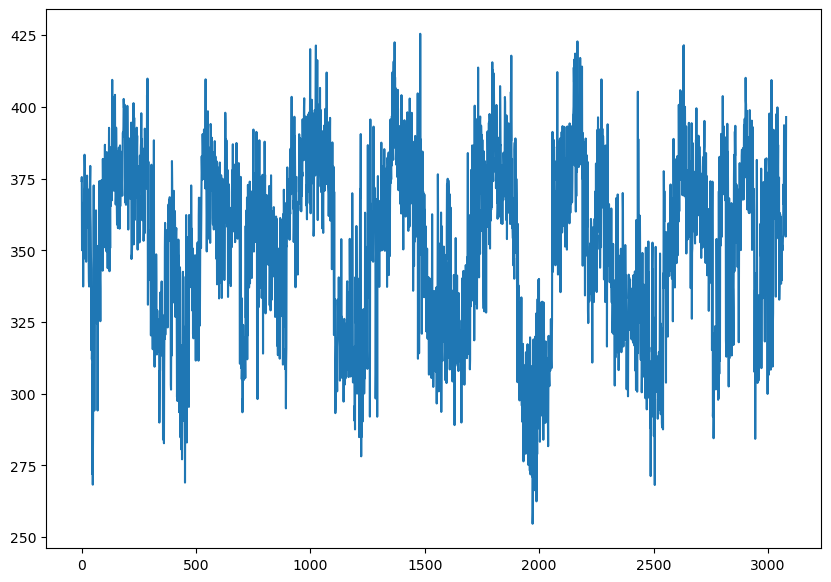

In [32]:

plt.plot(data[i])
# plt.plot(lc_filtered)

In [13]:
from sklearn.decomposition import PCA

In [45]:
np.shape(data)

(267, 3080)

In [33]:
PCA(n_components=10).fit(data)

PCA(n_components=10)

In [40]:
transformed_data = pca.transform(data) 

In [42]:
np.shape(transformed_data)

(461, 461)

/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/matplotlib/collections.py:1080: UserWarning: Collection without array used. Make sure to specify the values to be colormapped via the `c` argument.
  warnings.warn("Collection without array used. Make sure to "


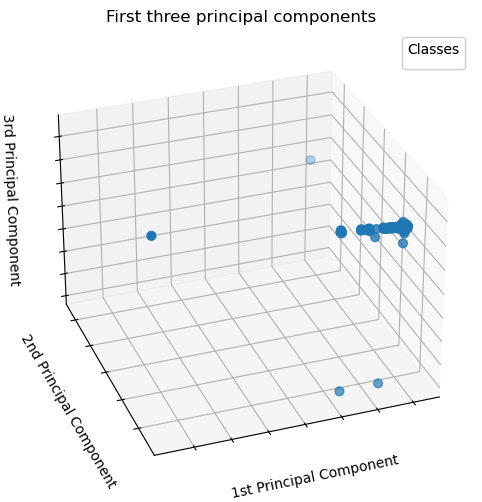

In [39]:

fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)

X_reduced = PCA(n_components=3).fit_transform(data)
scatter = ax.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    X_reduced[:, 2],
    # c=iris.target,
    s=40,
)

ax.set(
    title="First three principal components",
    xlabel="1st Principal Component",
    ylabel="2nd Principal Component",
    zlabel="3rd Principal Component",
)
ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])
ax.zaxis.set_ticklabels([])

# Add a legend
legend1 = ax.legend(
    scatter.legend_elements()[0],
    # iris.target_names.tolist(),
    loc="upper right",
    title="Classes",
)
ax.add_artist(legend1)

plt.show()

Explained variance ratio:
[9.77100990e-01 7.97984229e-03 4.91589008e-03 3.99816895e-03
 2.77721783e-03 9.11699118e-04 4.00514277e-04 2.39315570e-04
 1.96383418e-04 1.07184374e-04 1.02540146e-04 9.96380848e-05
 8.67623040e-05 7.77673558e-05 5.19447935e-05 4.76866195e-05
 4.14817475e-05 3.58531706e-05 3.34252550e-05 3.25425337e-05
 2.88645755e-05 2.84750984e-05 2.66713193e-05 2.49988163e-05
 2.39008467e-05 2.33579692e-05 2.15022276e-05 2.05583777e-05
 1.94267498e-05 1.81756373e-05 1.65570605e-05 1.55047058e-05
 1.47442666e-05 1.44513913e-05 1.40824309e-05 1.28103117e-05
 1.13841472e-05 1.11125916e-05 1.04097005e-05 1.00478595e-05
 9.79015470e-06 9.08719126e-06 8.97594972e-06 8.81008035e-06
 8.44900381e-06 8.15237850e-06 8.09424120e-06 7.73716033e-06
 7.40588516e-06 7.29818956e-06 6.81011392e-06 6.59158842e-06
 6.47244304e-06 6.32837077e-06 5.98112510e-06 5.73427280e-06
 5.54495805e-06 5.52799727e-06 5.23025614e-06 5.03634002e-06
 4.96329645e-06 4.83534633e-06 4.56043910e-06 4.50586657e-0

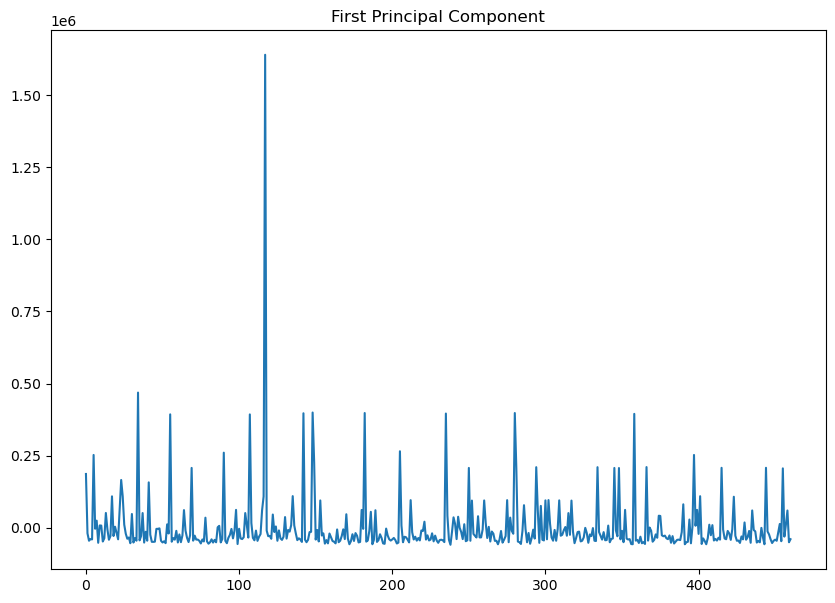

In [35]:
# Five observed series influenced by common factor + noise


# 3. Apply PCA
pca = PCA()
principal_components = pca.fit_transform(data)

# Explained variance
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

# 4. Plot first principal component
plt.figure()
plt.plot(principal_components[:, 0])
plt.title("First Principal Component")
plt.show()

In [14]:
from pca_denoise_lightcurves import pca_denoise, plot_elbow
import numpy as np

chosen k: 7


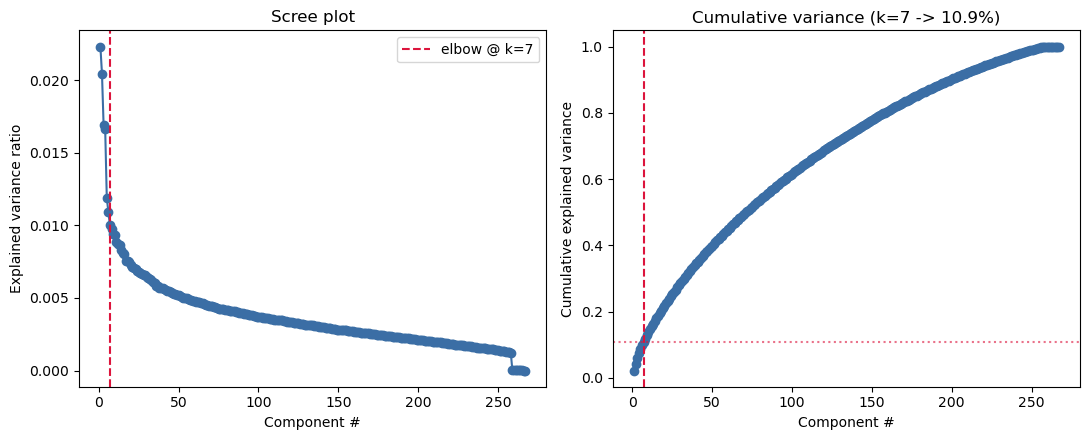

In [62]:


X = data  # shape (n_curves, n_timepoints)

X_denoised, info = pca_denoise(X, k=7, standardize=True)  # k=None -> auto elbow
print("chosen k:", info["k"])
plot_elbow(info["explained_variance_ratio"], info["k"])

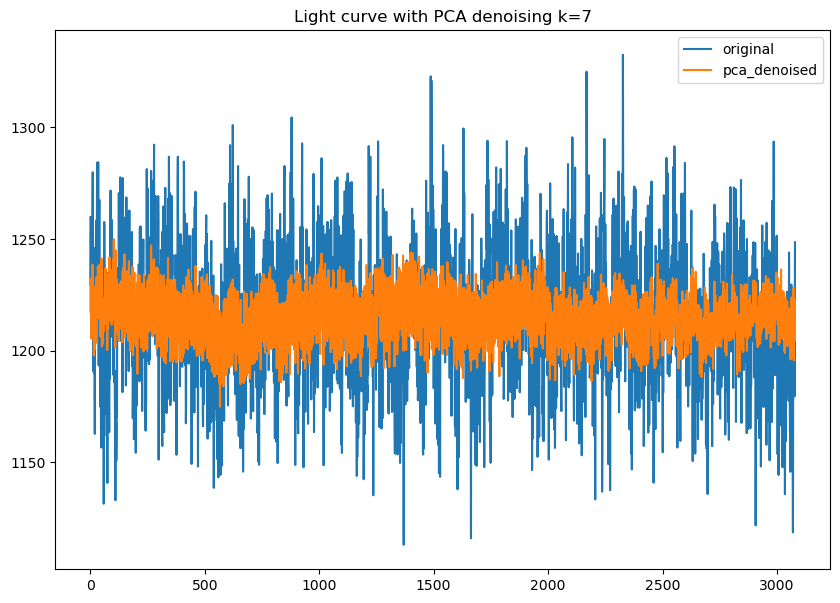

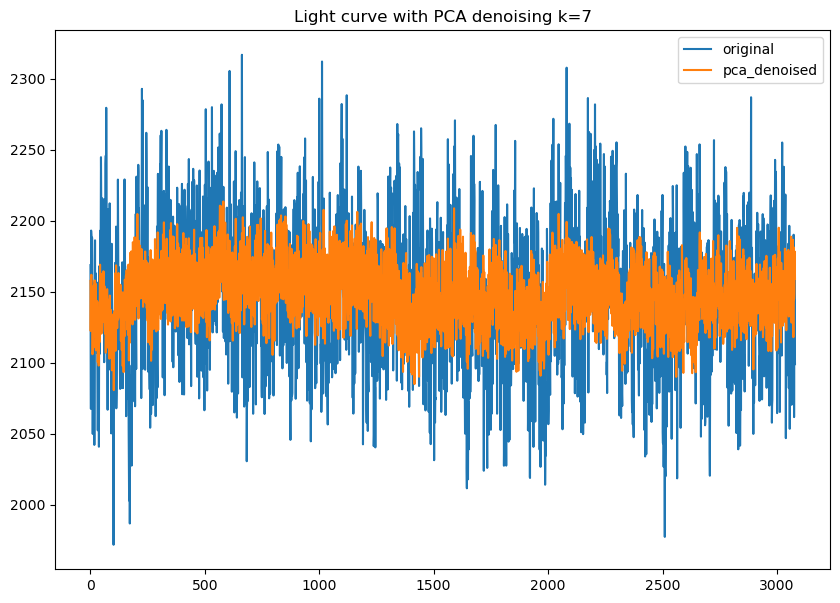

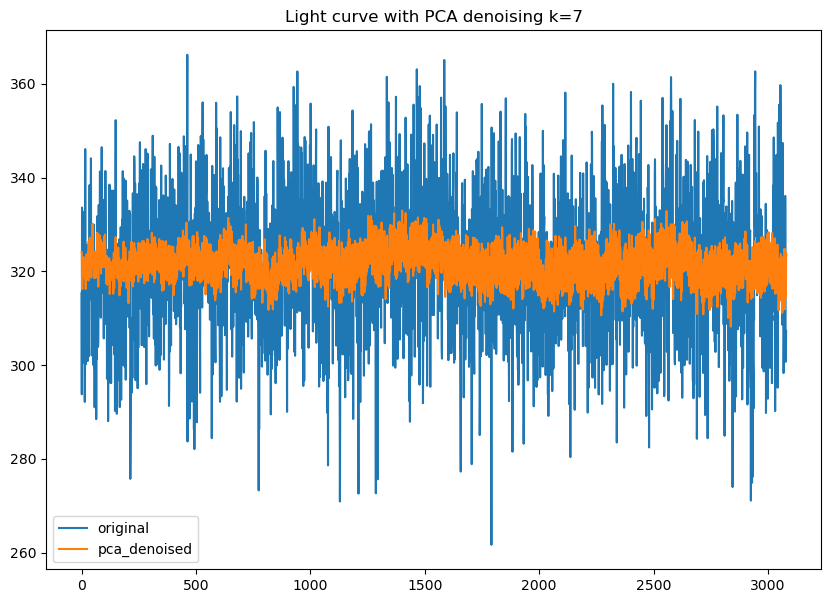

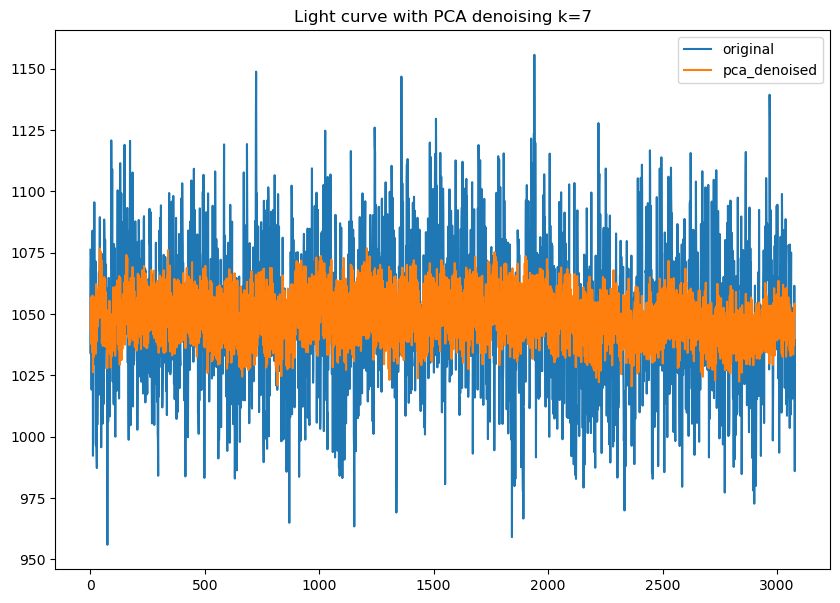

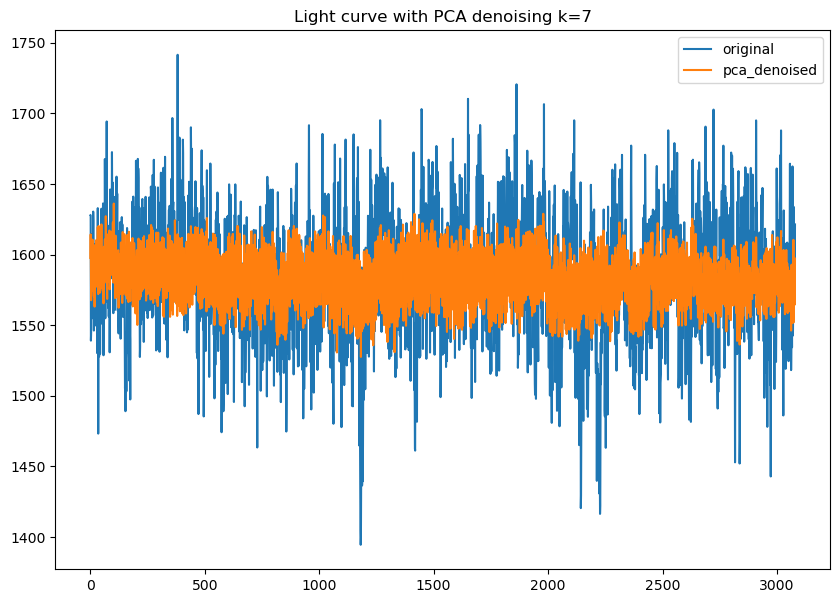

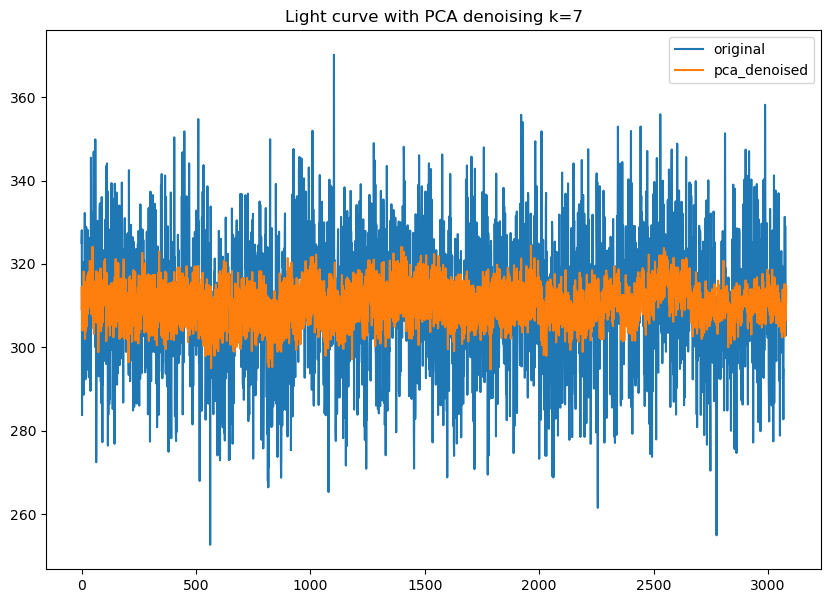

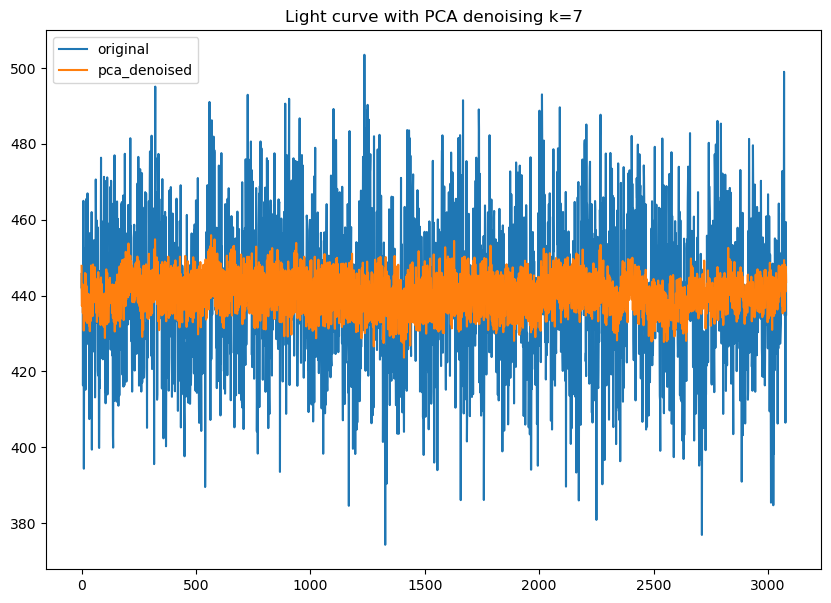

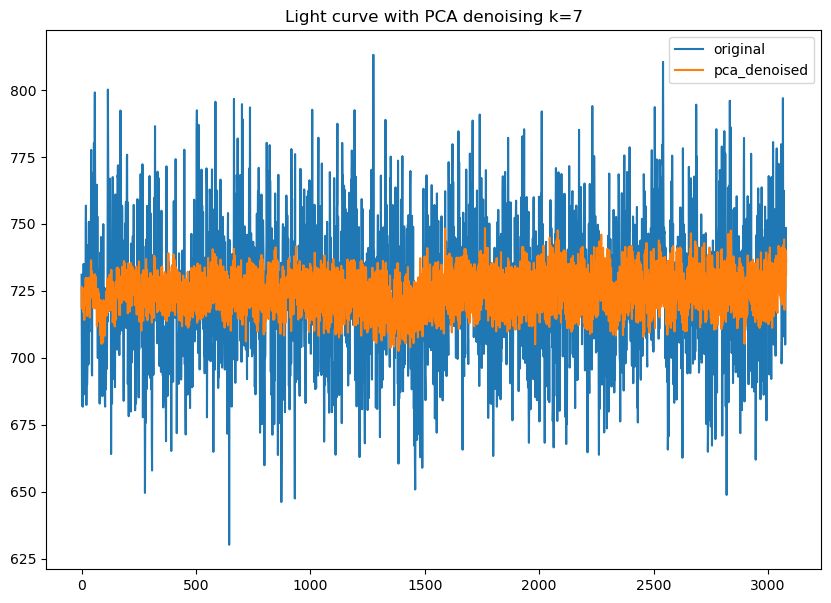

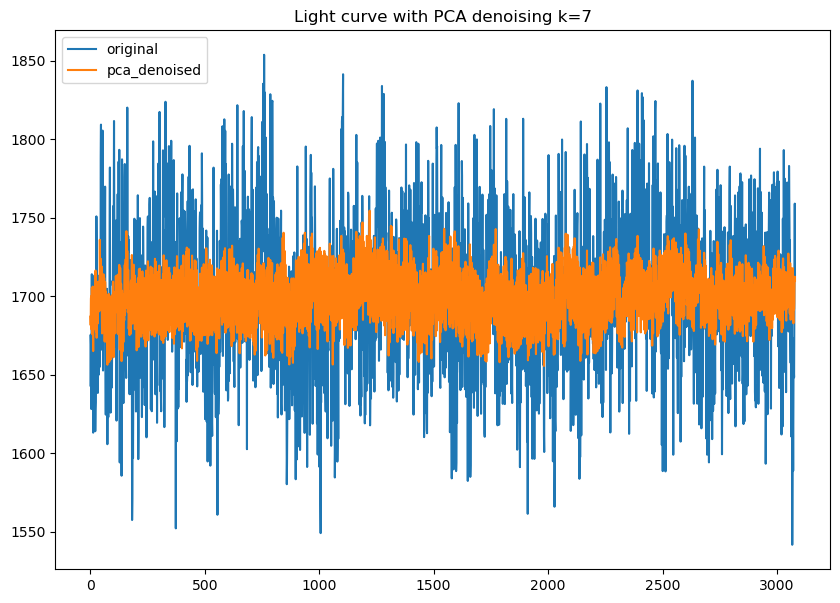

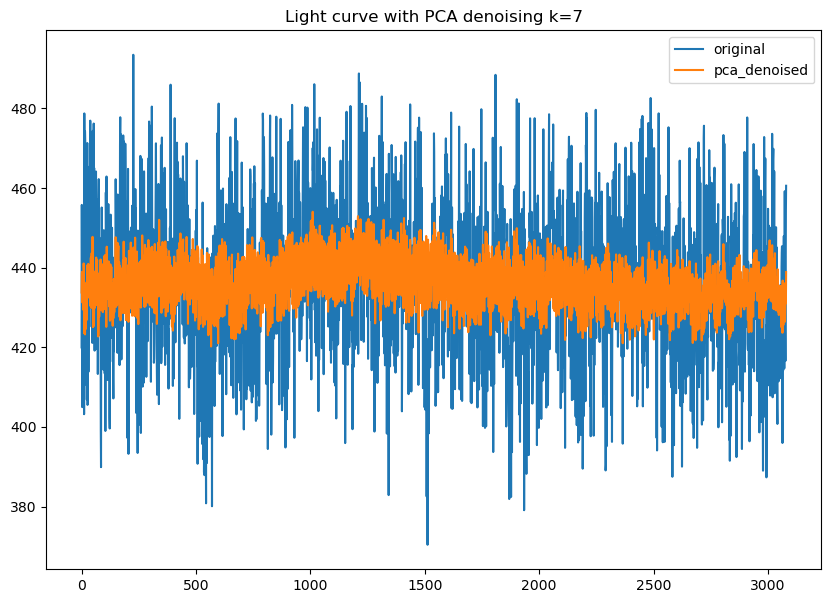

In [63]:
for i in range(0,10):
    plt.plot(data[i], label=
            'original')
    plt.plot(X_denoised[i], label='pca_denoised')
    plt.legend()
    plt.title('Light curve with PCA denoising k='+str(info["k"]))
    plt.show()

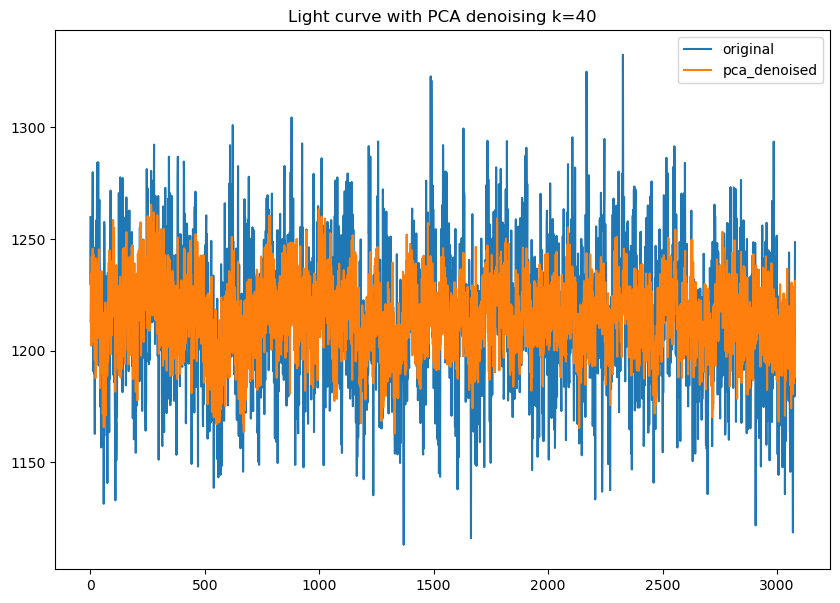

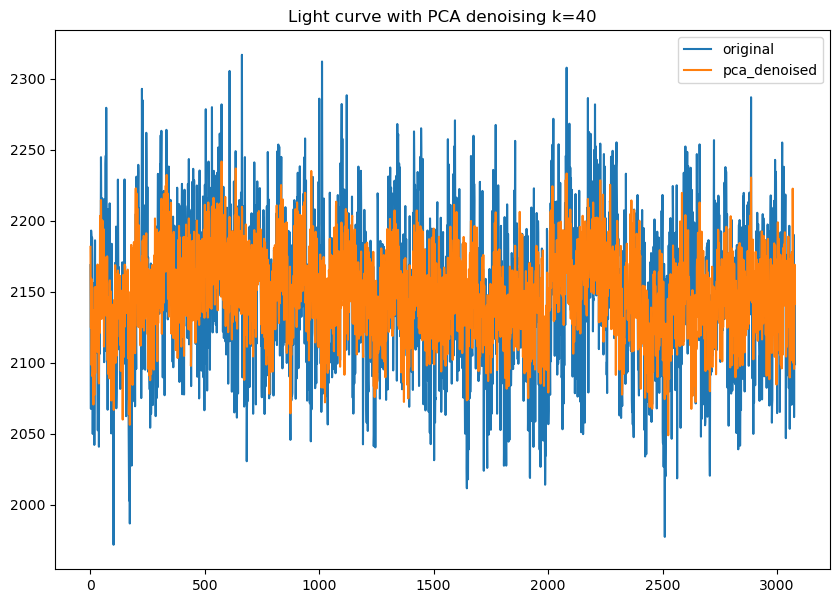

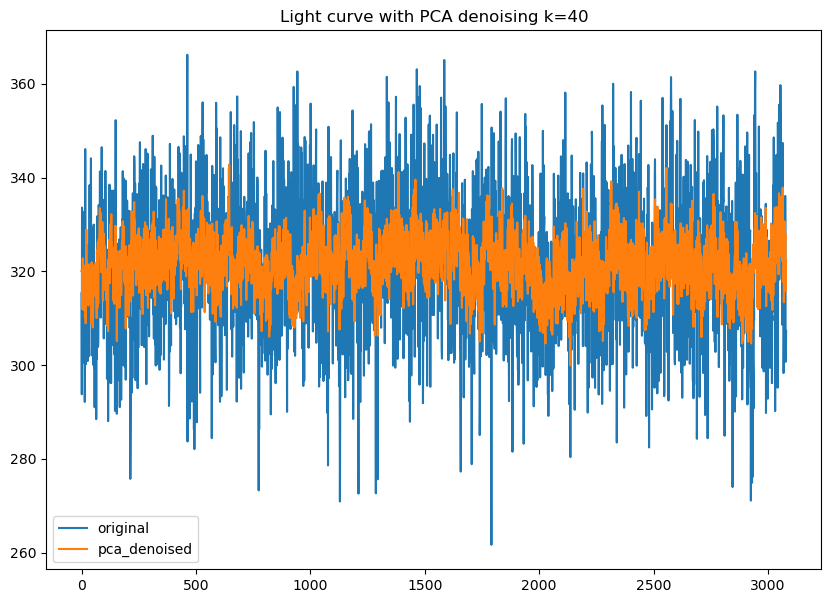

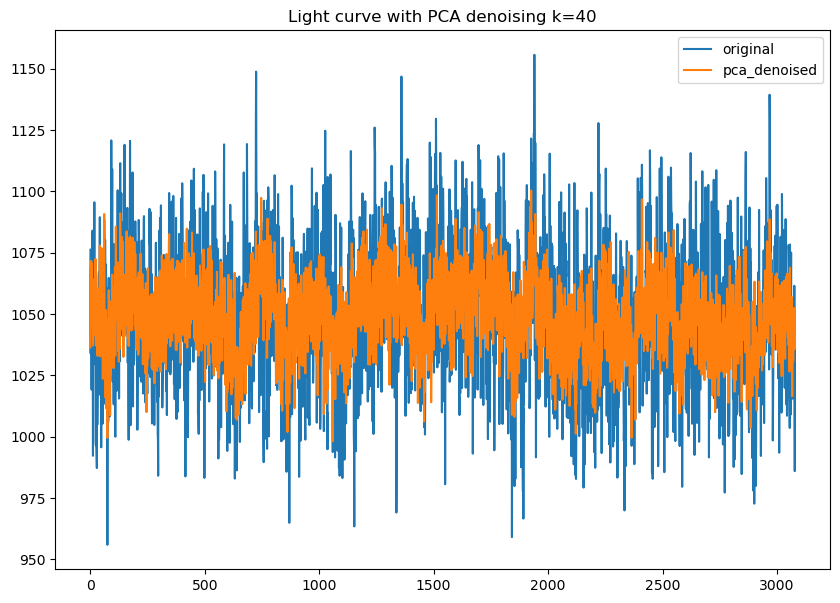

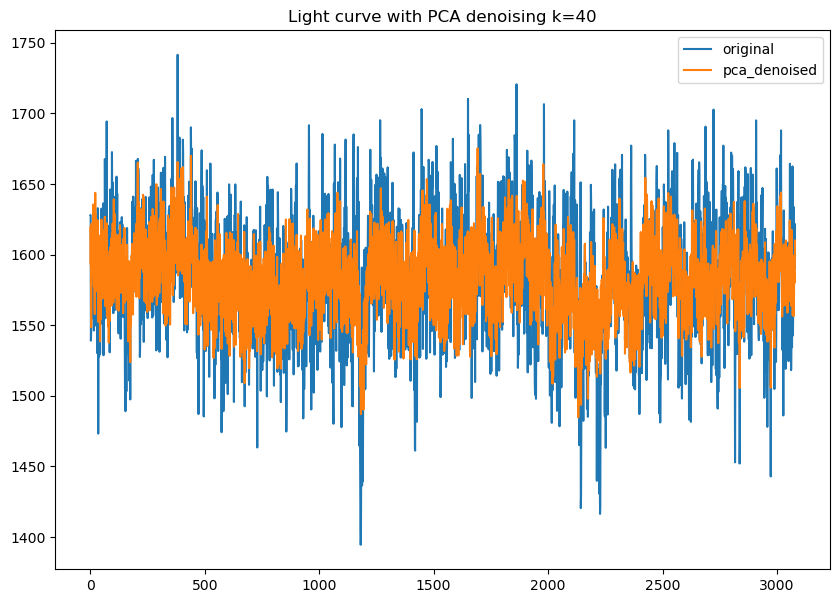

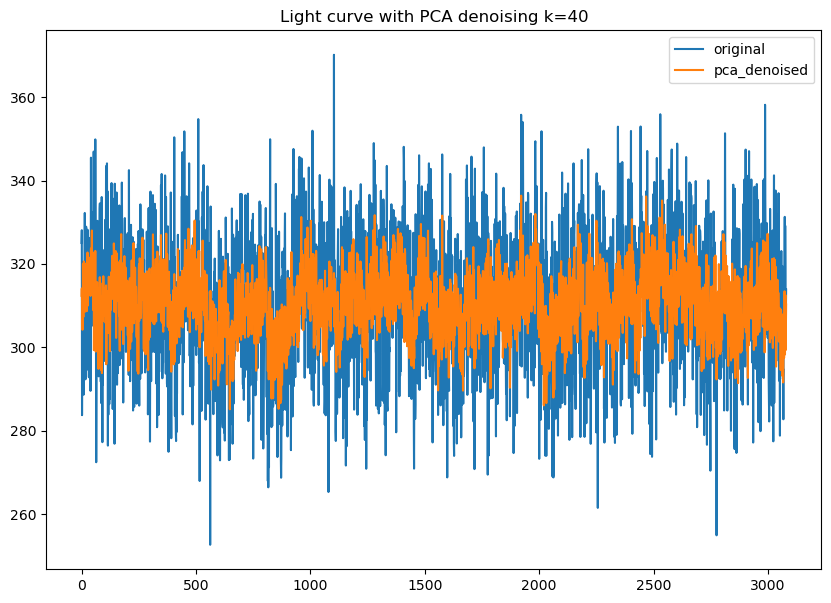

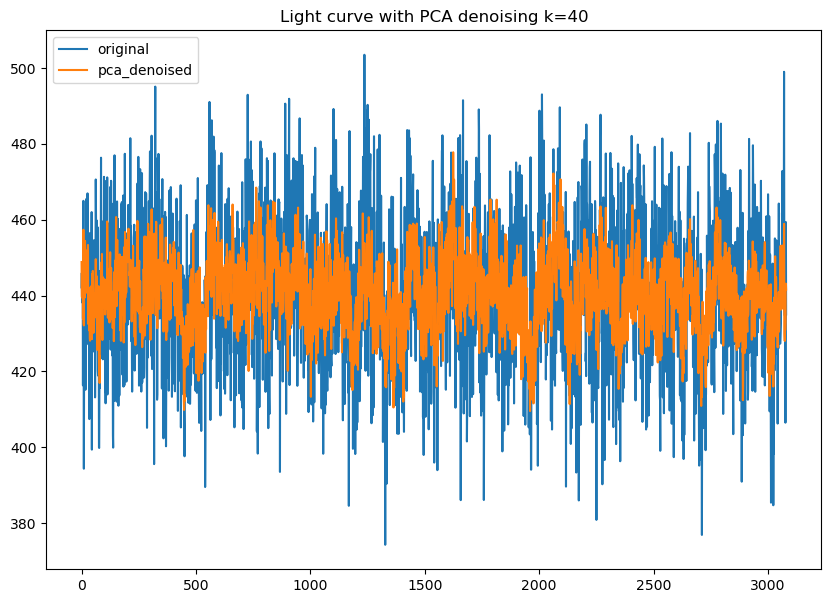

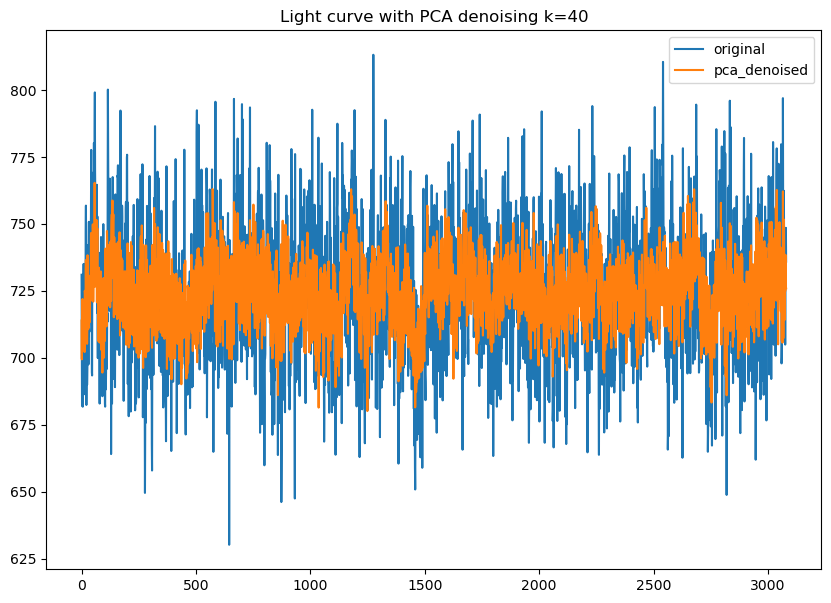

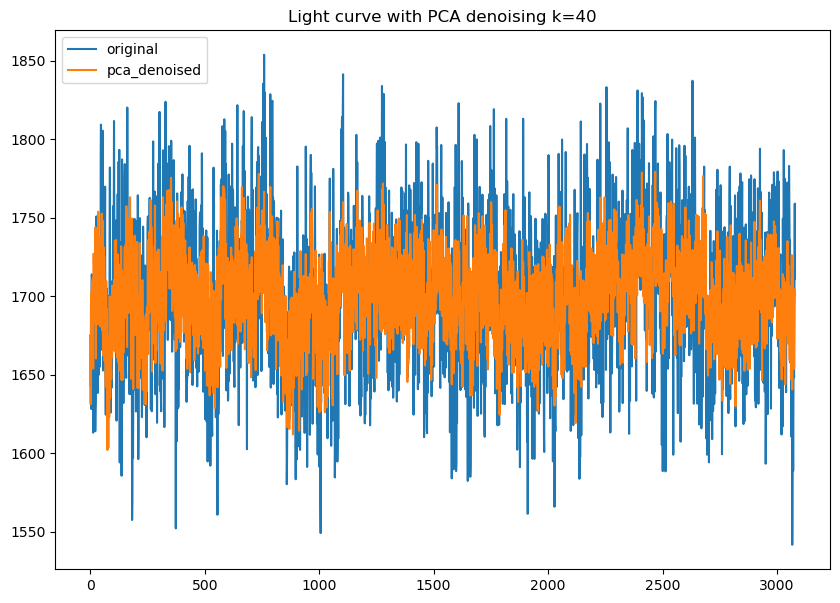

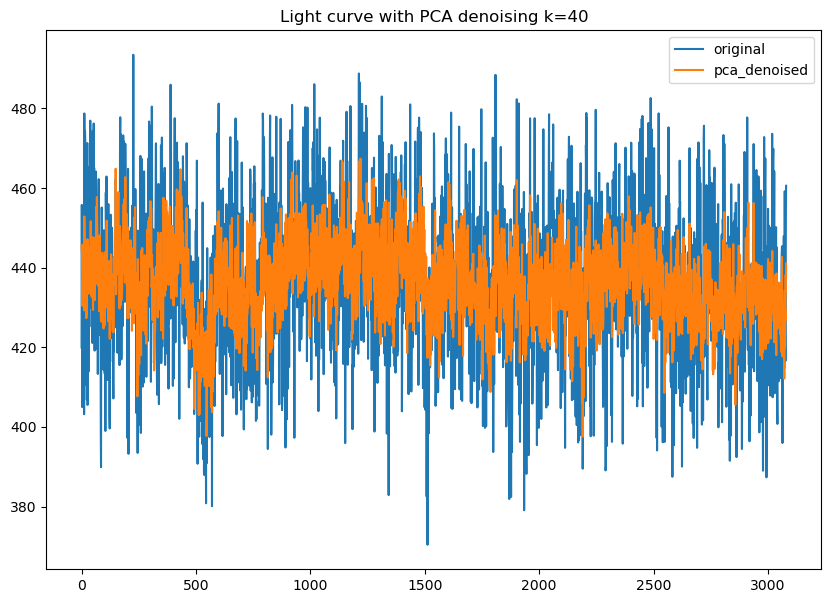

In [60]:
for i in range(0,10):
    plt.plot(data[i], label=
            'original')
    plt.plot(X_denoised[i], label='pca_denoised')
    plt.legend()
    plt.title('Light curve with PCA denoising k='+str(info["k"]))
    plt.show()

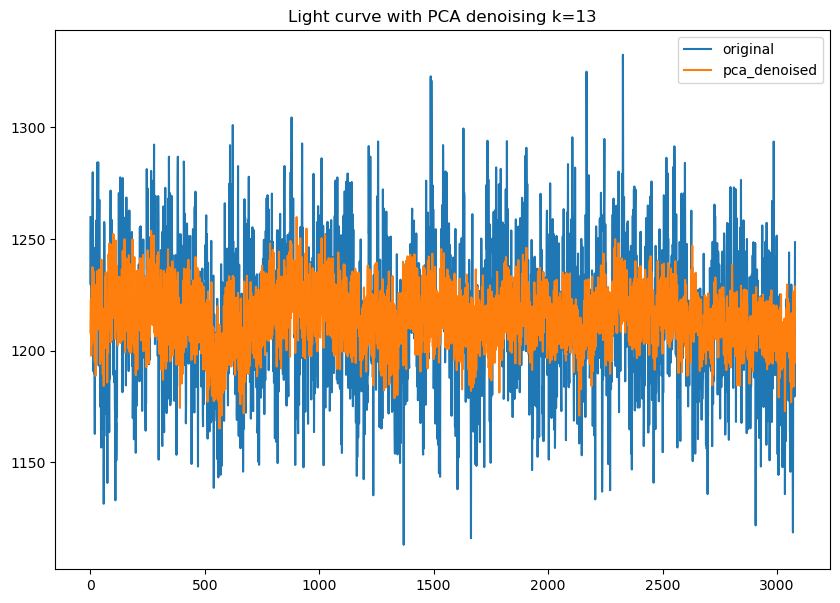

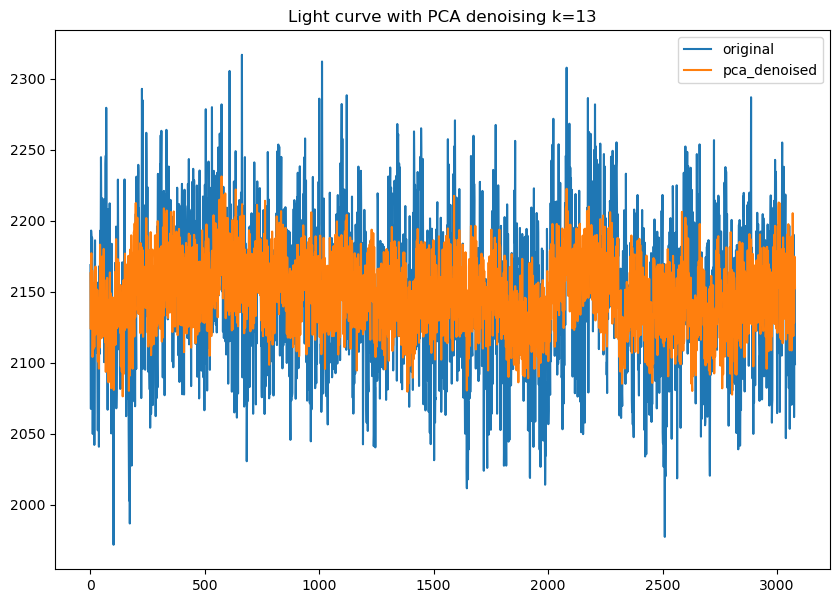

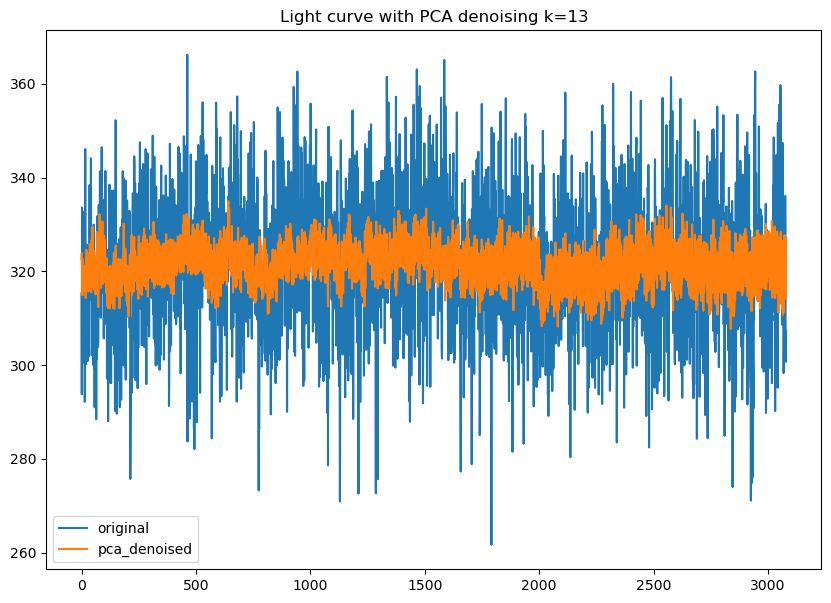

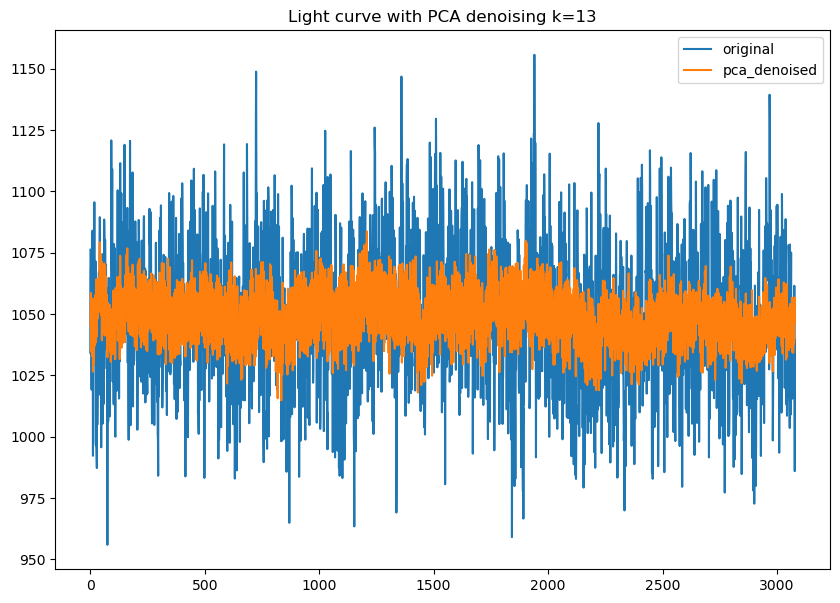

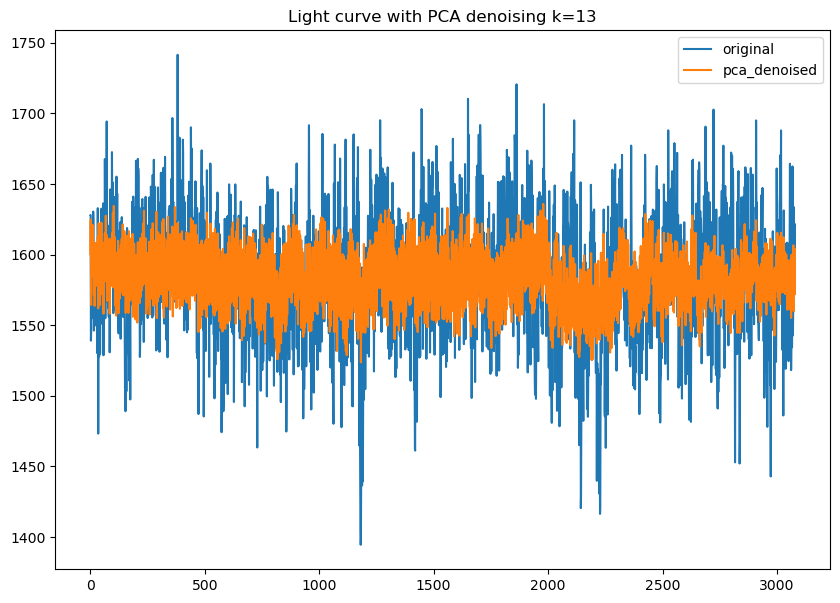

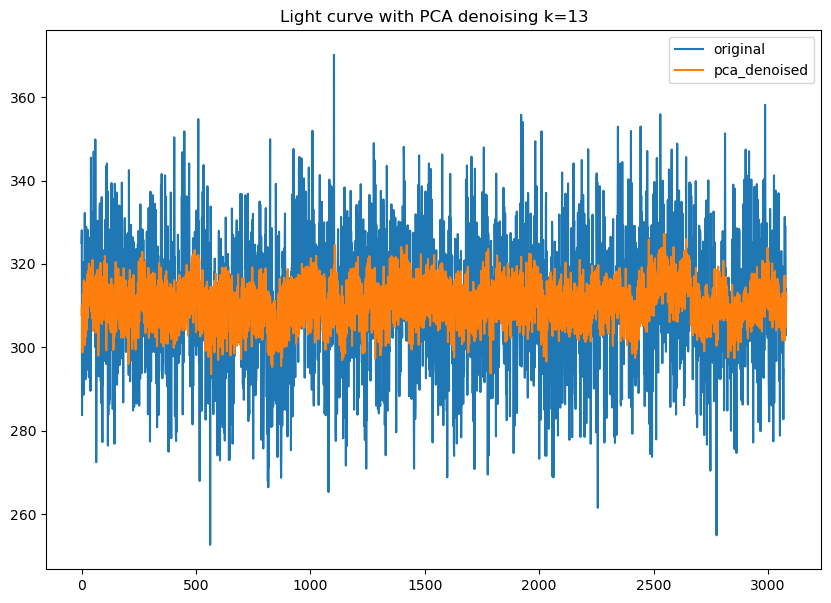

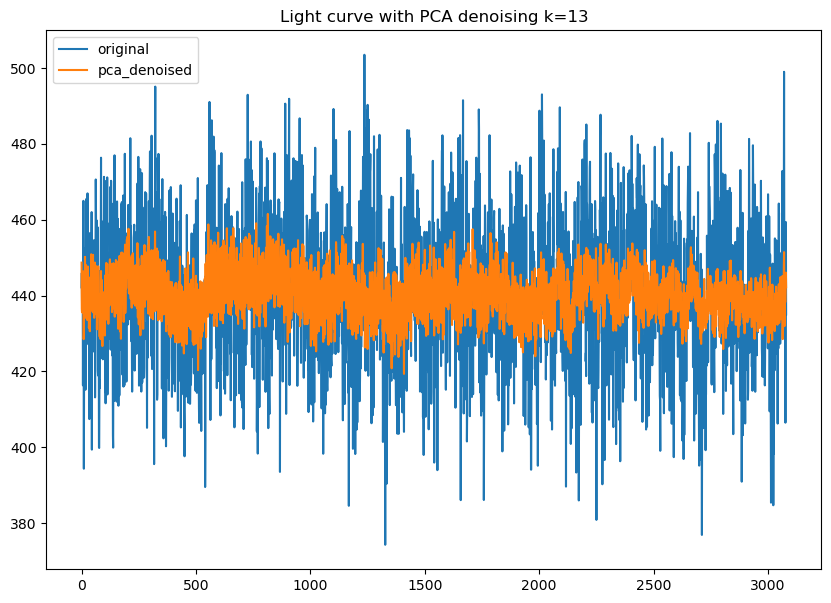

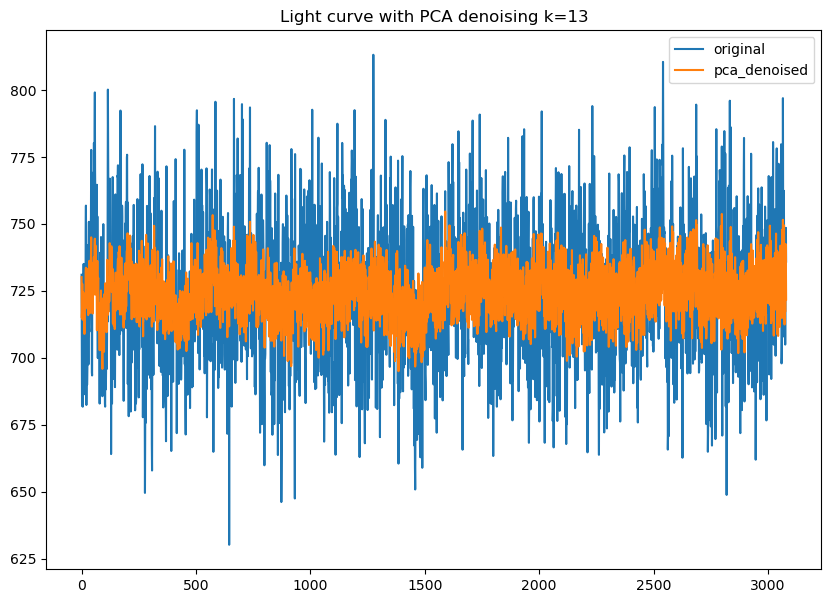

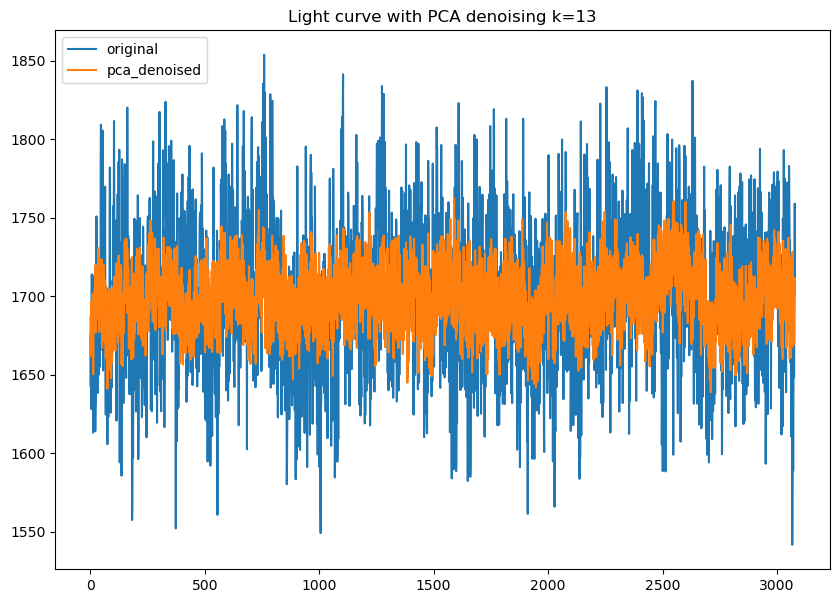

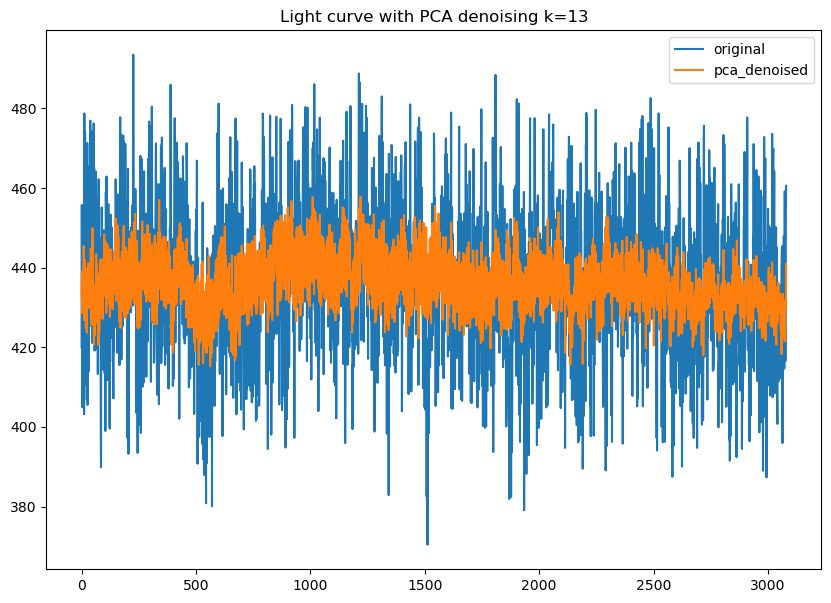

In [58]:
for i in range(0,10):
    plt.plot(data[i], label=
            'original')
    plt.plot(X_denoised[i], label='pca_denoised')
    plt.legend()
    plt.title('Light curve with PCA denoising k='+str(info["k"]))
    plt.show()

In [ ]:
#okay now i have to try to align the stars in time
#let's start with 

In [5]:
pred = pd.read_csv('/lustre/lrspec/ZTF_data/random_forest_training/predictions_reupdated.csv', names=['filename', 'binary', 'rf'])

In [6]:
good = pred[pred['binary']==0]['filename']

In [73]:
good[0]

'lightcurve_ztf_20221020138241_000686_zi_c11_x_0023_4_1499_1443.csv'

In [ ]:
from astropy import fits

In [74]:
hdul = fits.open('/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c11_x_0023.fits.fz')

In [ ]:
hdul[1].header

In [75]:
hdul[0].header

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    0 / number of data axes                            
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
ORIGIN  = 'Zwicky Transient Facility' / Data origin                             
OBSERVER= 'ZTF Robotic Observing Software' / Observer                           
ROBOSOFT= '1.1 August 1, 2022' / Robotic software version                       
FITSSOFT= '1.1 August 1, 2022' / FITS software version                          
INSTRUME= 'ZTF/MOSAIC'         / Instrument name                                
DETECTOR= '        '           / Detector controller                            
DETSOFT = '        '        

In [ ]:
#ignore the above it was mid-conversation of a different conversation

In [79]:
len('lightcurve_ztf_20221020138241_000686_zi_c11_x_00')

48

In [77]:
good[0]

'lightcurve_ztf_20221020138241_000686_zi_c11_x_0023_4_1499_1443.csv'

In [3]:
#goal...
#make a function that takes the filename of the begining one
#loads it
#loads the rest of them
#concatenates it
#subtracts the beginning and end to make it a standard size
def make_big_array(filename, total_len = 3080*28):
    # filename_list = []
    lcs_total = []
    
    for i in range(0, 29):
        new_filename = filename[:48]+f'{int(i):02}'+filename[50:]
        # filename_list.append(new_filename)
        lc = pd.read_csv(lightcurve_path+new_filename)['flux_hap_2']
        lcs_total = np.hstack((lcs_total,lc))
    closest_y = int(filename[-8:-4])
    lcs_adjust = lcs_total[closest_y:total_len+closest_y]
    return  lcs_adjust
     
    
        

In [7]:
lcs_adjust = make_big_array(good[0])

In [113]:
lcs_adjust

array([860.93432617, 886.89691162, 882.07775879, ..., 919.95300293,
       923.28601074, 899.28503418])

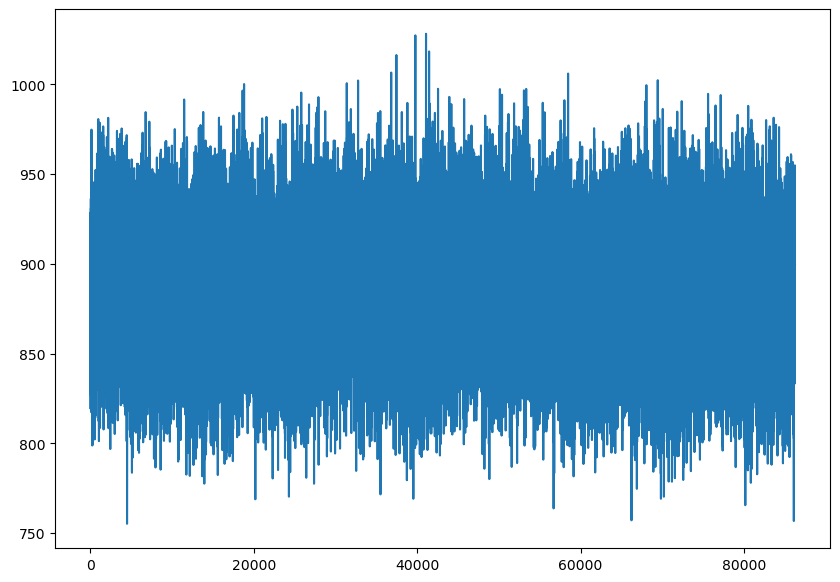

In [106]:
plt.plot(lcs_adjust)

In [8]:
all_lcs = [] 
for filename in good[:200].values:
    try:
        lcs_adjust = make_big_array(filename)
        all_lcs.append(lcs_adjust)
    except:
        continue

In [11]:
len(np.array(all_lcs))

182

chosen k: 7


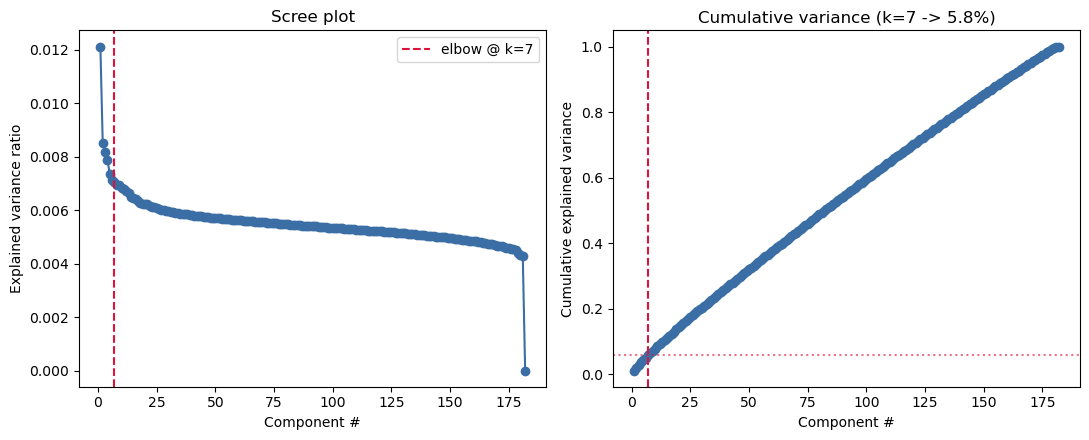

In [15]:

X_denoised, info = pca_denoise(all_lcs, k=7, standardize=True)  # k=None -> auto elbow
print("chosen k:", info["k"])
plot_elbow(info["explained_variance_ratio"], info["k"])

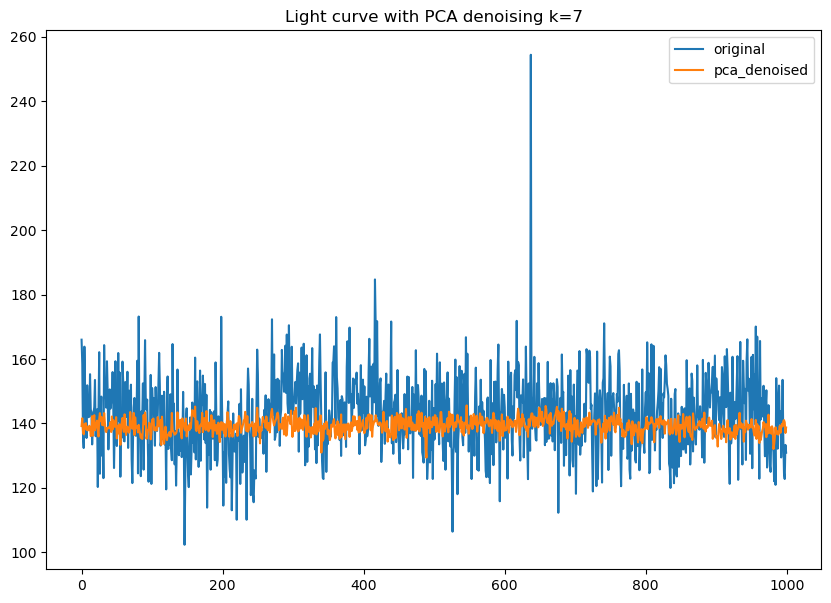

In [22]:
i=4
xmin = 29000
xmax = 30000

plt.plot(all_lcs[i][xmin:xmax], label=
        'original')
plt.plot(X_denoised[i][xmin:xmax], label='pca_denoised')
plt.legend()
plt.title('Light curve with PCA denoising k='+str(info["k"]))
plt.show()

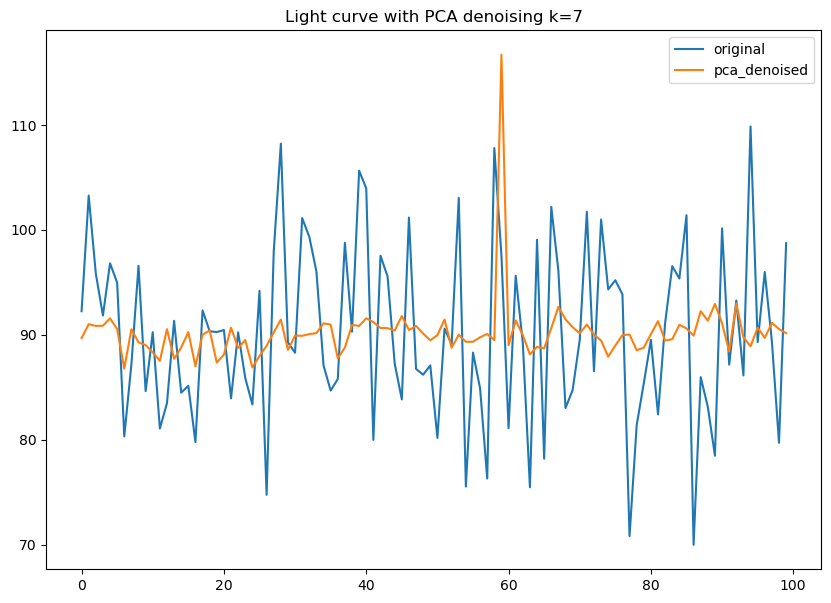

In [36]:
i=3
xmin = 16000
xmax = 16100

plt.plot(all_lcs[i][xmin:xmax], label=
        'original')
plt.plot(X_denoised[i][xmin:xmax], label='pca_denoised')
plt.legend()
plt.title('Light curve with PCA denoising k='+str(info["k"]))
plt.show()

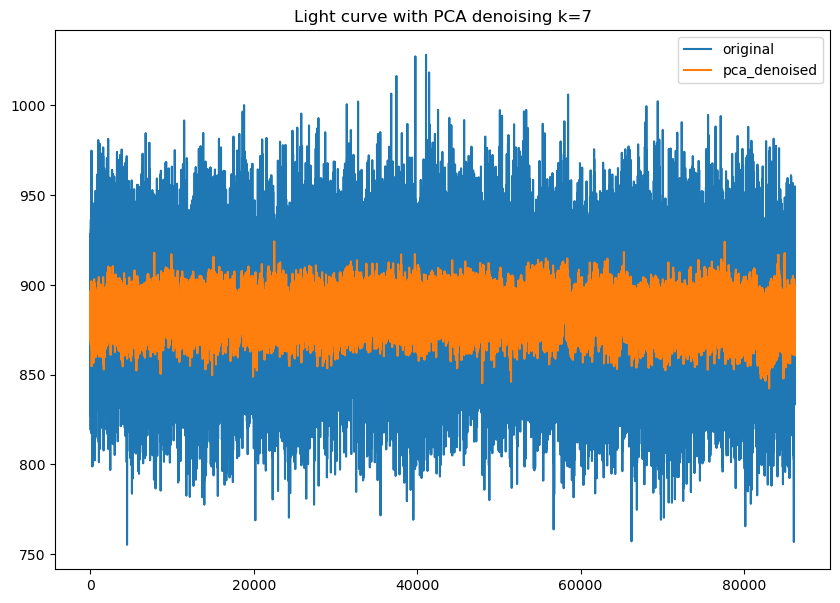

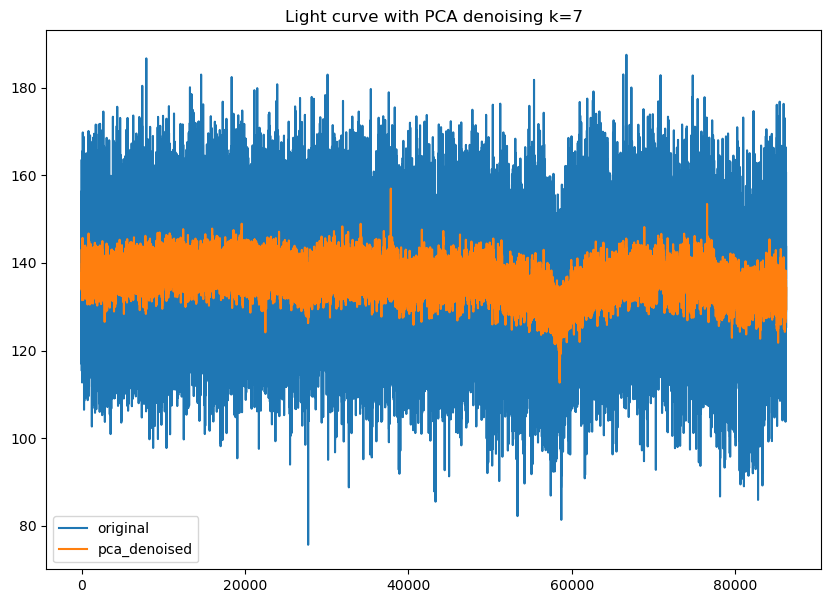

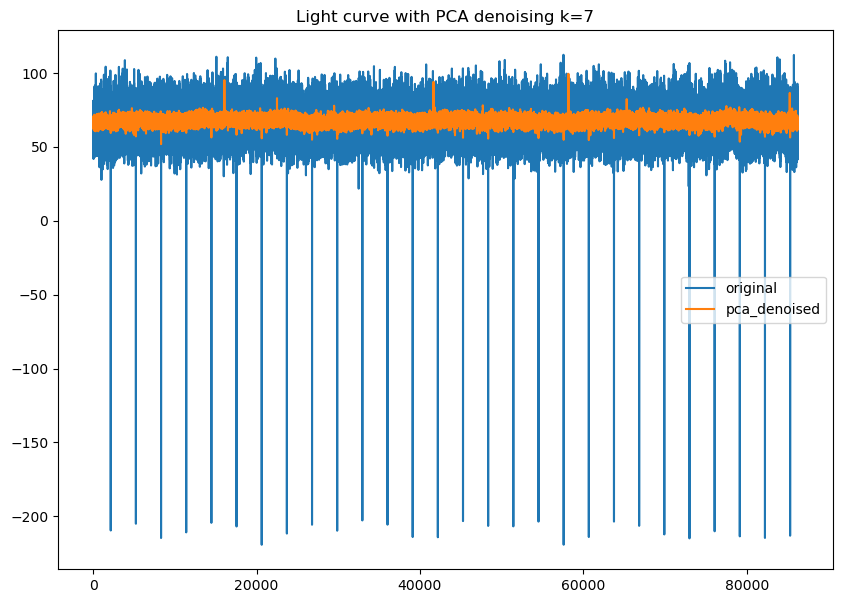

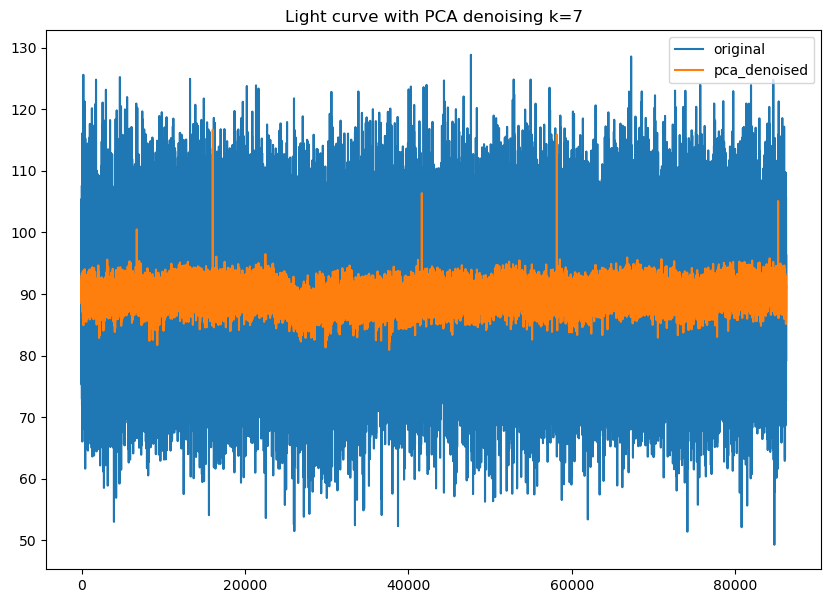

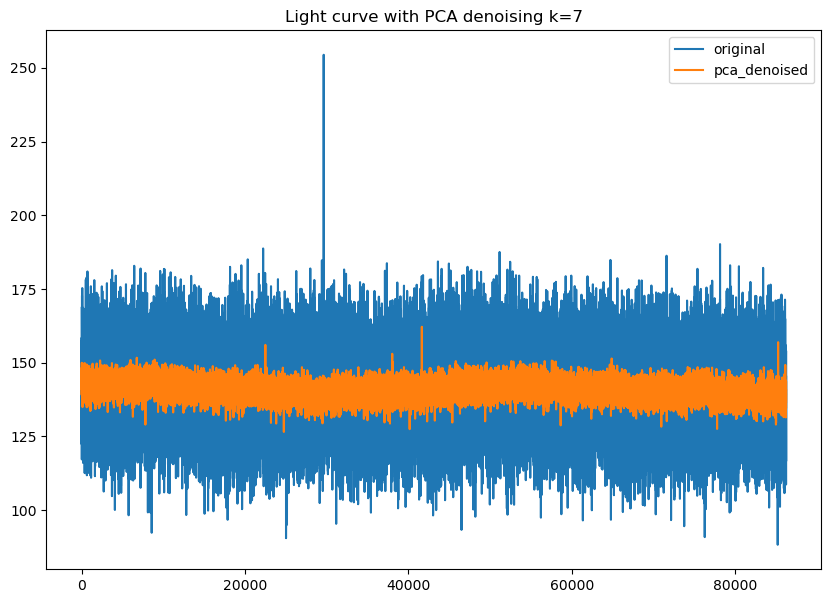

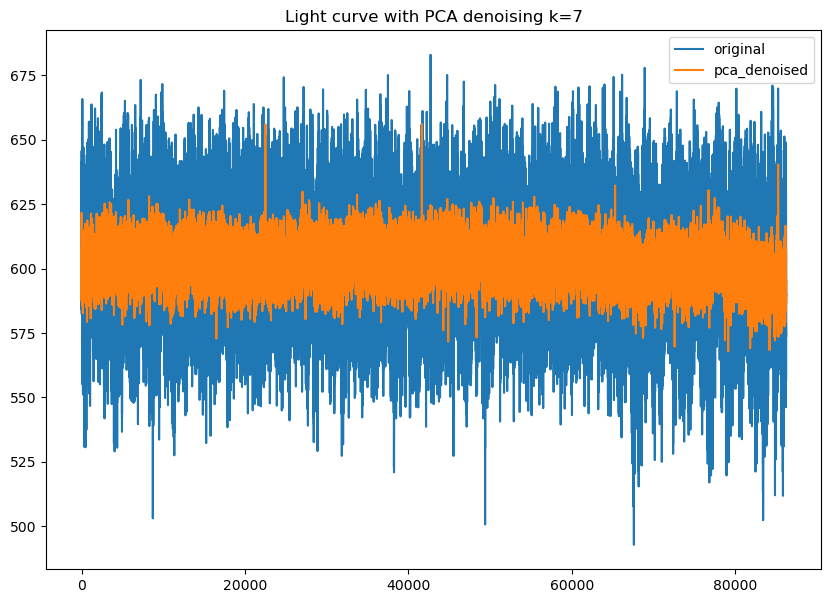

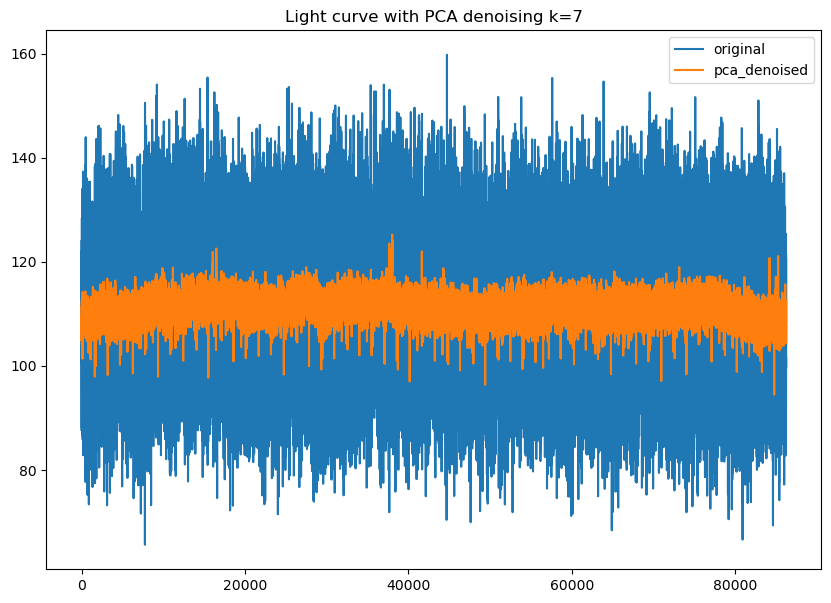

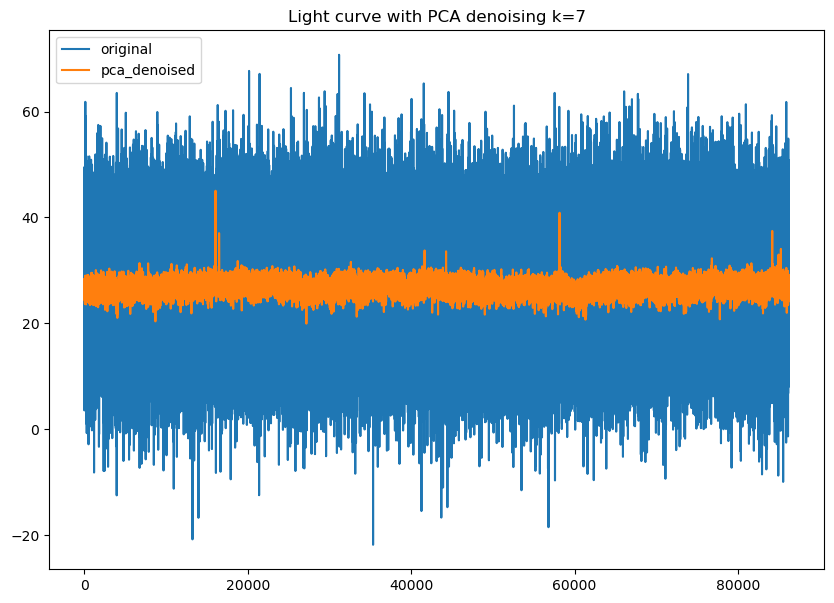

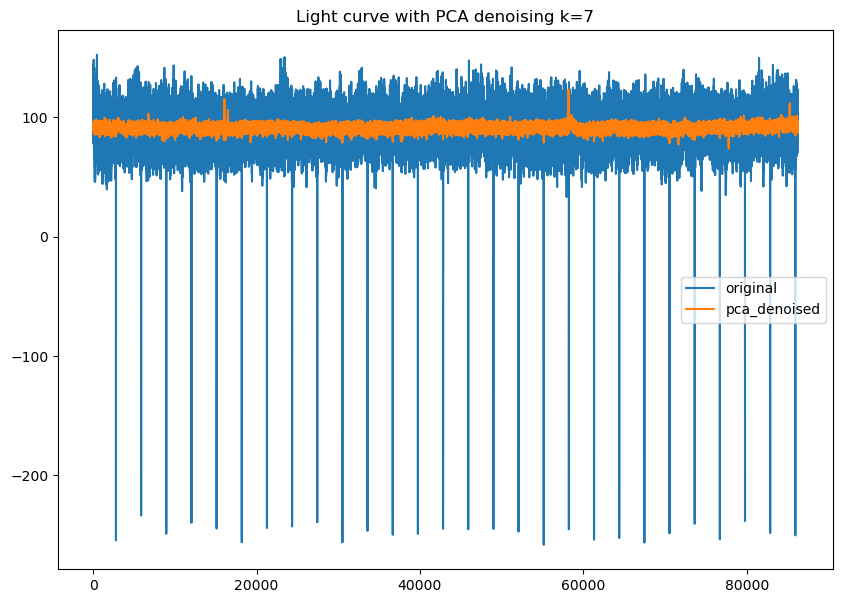

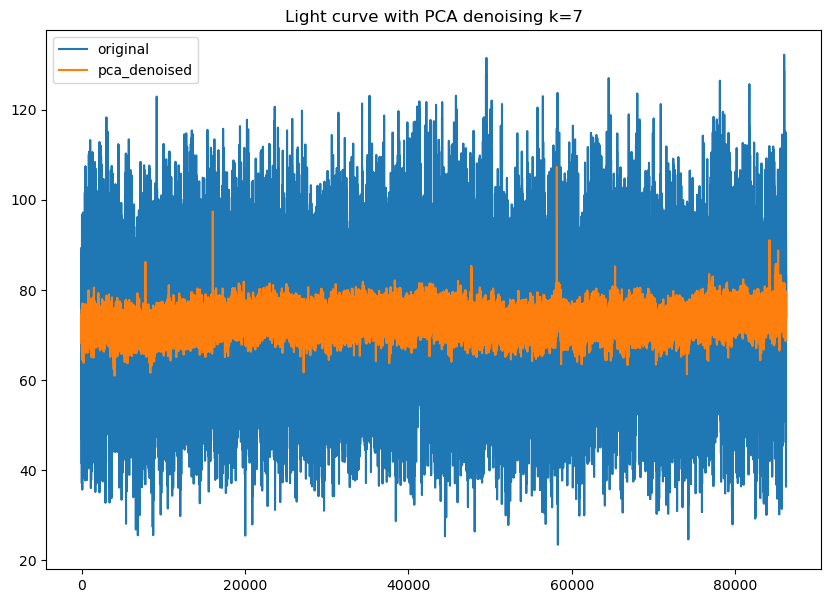

In [16]:
for i in range(0,10):
    plt.plot(all_lcs[i], label=
            'original')
    plt.plot(X_denoised[i], label='pca_denoised')
    plt.legend()
    plt.title('Light curve with PCA denoising k='+str(info["k"]))
    plt.show()